# Ames Housing — Preparación de datos y modelos clásicos de regresión

## Objetivo

Construir un flujo de Machine Learning para predecir `SalePrice` utilizando tres modelos de scikit-learn:

1. `LinearRegression`
2. `RandomForestRegressor`
3. `GradientBoostingRegressor`

Se parte del EDA y del notebook de preparación existentes. Se mantienen sus decisiones justificadas y se incorporan pipelines y validación cruzada para optimizar hiperparámetros sin utilizar información de Validation durante el entrenamiento.

## Criterio de evaluación

- El target se modela como `log1p(SalePrice)`, porque el EDA mostró una asimetría positiva marcada en el precio y una distribución más cercana a la normal luego de la transformación.
- Las métricas finales se calculan en la escala original de dólares: **MAE** y **RMSE**.
- La búsqueda de hiperparámetros se realiza únicamente con Training, mediante cross-validation.
- Validation se reserva para la evaluación final. No se utiliza para aprender medianas, modas, categorías, escalas ni hiperparámetros.

## 1. Configuración e imports

Se fija una semilla central para todos los componentes estocásticos. También se centralizan las rutas para facilitar la ejecución en otro entorno.

Si los CSV están en otra ubicación, modificar únicamente `TRAIN_PATH` y `VAL_PATH`.

In [3]:
%pip install -q pandas numpy scikit-learn matplotlib


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [20]:
%pip install jinja2

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [jinja2]

[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    make_scorer
)
from sklearn.model_selection import (
    KFold,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler
)

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
N_SPLITS = 5

TRAIN_PATH = Path("../ames-housing-desarrollo-estudiantes/train.csv")
VAL_PATH = Path("../ames-housing-desarrollo-estudiantes/validation.csv")

if not TRAIN_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró Training en: {TRAIN_PATH.resolve()}. "
        "Actualizá TRAIN_PATH con la ubicación correcta del archivo."
    )

if not VAL_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró Validation en: {VAL_PATH.resolve()}. "
        "Actualizá VAL_PATH con la ubicación correcta del archivo."
    )

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)

print("Training:", train_df.shape)
print("Validation:", val_df.shape)

Training: (1022, 81)
Validation: (219, 81)


## 2. Separación de predictoras y variable objetivo

Separamos `SalePrice` de las variables explicativas. `Id` no se utilizará como predictor porque identifica registros, pero no describe una característica de la vivienda.

A partir de este punto, las transformaciones se encapsulan dentro de los pipelines. Esto es importante: durante cada fold de cross-validation, los imputadores, codificadores y escaladores se ajustan solamente con la porción de entrenamiento de ese fold.

In [5]:
TARGET = "SalePrice"

if TARGET not in train_df.columns or TARGET not in val_df.columns:
    raise ValueError(f"Ambos archivos deben contener la columna {TARGET}.")

X_train = train_df.drop(columns=[TARGET]).copy()
y_train = train_df[TARGET].copy()

X_val = val_df.drop(columns=[TARGET]).copy()
y_val = val_df[TARGET].copy()

if (y_train <= 0).any() or (y_val <= 0).any():
    raise ValueError("SalePrice debe ser positivo para aplicar log1p.")

# Transformación determinista del target; no aprende parámetros de los datos.
y_train_log = np.log1p(y_train)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:", X_val.shape, "| y_val:", y_val.shape)

X_train: (1022, 80) | y_train: (1022,)
X_val: (219, 80) | y_val: (219,)


## 3. Decisiones de preparación derivadas del EDA

Se implementan las siguientes decisiones:

- **Valores faltantes con significado:** las variables categóricas que indican ausencia de pileta, garage, sótano, chimenea, cerco, etc. se completan con la categoría `"None"`. `GarageYrBlt` y `MasVnrArea` se completan con `0`.
- **`LotFrontage`:** se imputa con la mediana de `Neighborhood`; si un barrio no tiene una mediana disponible, se utiliza la mediana global aprendida en el conjunto de entrenamiento del fold.
- **`Electrical`:** se imputa con la moda aprendida en el entrenamiento del fold.
- **`MSSubClass`:** se convierte a texto porque es un código de tipo de vivienda, no una magnitud numérica.
- **Variables ordinales:** las categorías de calidad/condición conservan su orden mediante `OrdinalEncoder`.
- **Variables nominales:** se codifican con One-Hot Encoding. `handle_unknown="ignore"` permite procesar categorías que no hayan aparecido al ajustar el encoder.
- **Variables numéricas sesgadas:** para Linear Regression se aplica `log1p` a áreas y superficies continuas sesgadas y luego se escalan. Los modelos de árboles no necesitan escalado ni transformación de skew.
- **Feature engineering:** se agregan superficies, baños equivalentes, antigüedad, remodelación, porches e indicadores de existencia.

La transformación especial de `LotFrontage` y las imputaciones se implementan en un transformer propio para que se vuelvan a aprender dentro de cada fold.

In [6]:
class AmesFeatureEngineer(BaseEstimator, TransformerMixin):
    """Limpieza semántica e ingeniería de variables para Ames Housing."""

    CATEGORICAL_ABSENCE = [
        "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
        "GarageType", "GarageFinish", "GarageQual", "GarageCond",
        "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
        "BsmtFinType2", "MasVnrType"
    ]

    NUMERIC_ABSENCE = ["GarageYrBlt", "MasVnrArea"]

    def fit(self, X, y=None):
        X = X.copy()

        # Las estadísticas se aprenden exclusivamente con el fold de entrenamiento.
        if "LotFrontage" in X.columns and "Neighborhood" in X.columns:
            self.lotfrontage_medians_ = (
                X.groupby("Neighborhood")["LotFrontage"].median()
            )
            self.lotfrontage_global_median_ = X["LotFrontage"].median()
        else:
            self.lotfrontage_medians_ = pd.Series(dtype=float)
            self.lotfrontage_global_median_ = 0.0

        if "Electrical" in X.columns:
            modes = X["Electrical"].mode(dropna=True)
            self.electrical_mode_ = modes.iloc[0] if not modes.empty else "Missing"
        else:
            self.electrical_mode_ = "Missing"

        # Utilities se elimina solamente si es constante en el fold de entrenamiento.
        self.drop_utilities_ = (
            "Utilities" in X.columns
            and X["Utilities"].nunique(dropna=False) <= 1
        )

        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        X = X.copy()

        # El identificador no aporta información descriptiva al modelo.
        X = X.drop(columns=["Id"], errors="ignore")

        if self.drop_utilities_:
            X = X.drop(columns=["Utilities"], errors="ignore")

        # MSSubClass es un código nominal, no una variable continua.
        if "MSSubClass" in X.columns:
            X["MSSubClass"] = X["MSSubClass"].astype("string").astype(object)

        # NaN representa que la característica no existe.
        for col in self.CATEGORICAL_ABSENCE:
            if col in X.columns:
                X[col] = X[col].fillna("None")

        for col in self.NUMERIC_ABSENCE:
            if col in X.columns:
                X[col] = X[col].fillna(0)

        # LotFrontage: mediana por barrio y, como respaldo, mediana global.
        if "LotFrontage" in X.columns:
            if "Neighborhood" in X.columns:
                group_medians = X["Neighborhood"].map(self.lotfrontage_medians_)
                X["LotFrontage"] = X["LotFrontage"].fillna(group_medians)
            X["LotFrontage"] = X["LotFrontage"].fillna(
                self.lotfrontage_global_median_
            )

        # Electrical: la moda se aprende en fit(), nunca desde Validation.
        if "Electrical" in X.columns:
            X["Electrical"] = X["Electrical"].fillna(self.electrical_mode_)

        # Feature engineering: las variables de origen se encuentran en Ames Housing.
        def safe_sum(frame, columns):
            existing = [col for col in columns if col in frame.columns]
            return frame[existing].fillna(0).sum(axis=1)

        if all(c in X.columns for c in ["TotalBsmtSF", "1stFlrSF", "2ndFlrSF"]):
            X["TotalSF"] = safe_sum(
                X, ["TotalBsmtSF", "1stFlrSF", "2ndFlrSF"]
            )

        if all(c in X.columns for c in [
            "FullBath", "HalfBath", "BsmtFullBath", "BsmtHalfBath"
        ]):
            X["TotalBathrooms"] = (
                X["FullBath"].fillna(0)
                + 0.5 * X["HalfBath"].fillna(0)
                + X["BsmtFullBath"].fillna(0)
                + 0.5 * X["BsmtHalfBath"].fillna(0)
            )

        if all(c in X.columns for c in ["YrSold", "YearBuilt"]):
            X["HouseAgeAtSale"] = X["YrSold"] - X["YearBuilt"]

        if all(c in X.columns for c in ["YrSold", "YearRemodAdd"]):
            X["RemodAgeAtSale"] = X["YrSold"] - X["YearRemodAdd"]

        if all(c in X.columns for c in ["YearRemodAdd", "YearBuilt"]):
            X["IsRemodeled"] = (
                X["YearRemodAdd"] != X["YearBuilt"]
            ).astype(int)

        porch_cols = [
            "OpenPorchSF", "3SsnPorch", "EnclosedPorch",
            "ScreenPorch", "WoodDeckSF"
        ]
        if all(c in X.columns for c in porch_cols):
            X["TotalPorchSF"] = safe_sum(X, porch_cols)

        indicators = {
            "HasGarage": "GarageArea",
            "HasBsmt": "TotalBsmtSF",
            "HasFireplace": "Fireplaces",
            "HasPool": "PoolArea",
            "Has2ndFloor": "2ndFlrSF",
            "HasMasVnr": "MasVnrArea"
        }

        for new_col, source_col in indicators.items():
            if source_col in X.columns:
                X[new_col] = (X[source_col].fillna(0) > 0).astype(int)

        return X

    def get_feature_names_out(self, input_features=None):
        names = list(self.feature_names_in_)
        names = [name for name in names if name != "Id"]
        if self.drop_utilities_:
            names = [name for name in names if name != "Utilities"]

        additions = [
            "TotalSF", "TotalBathrooms", "HouseAgeAtSale",
            "RemodAgeAtSale", "IsRemodeled", "TotalPorchSF",
            "HasGarage", "HasBsmt", "HasFireplace",
            "HasPool", "Has2ndFloor", "HasMasVnr"
        ]
        return np.asarray(names + [name for name in additions if name not in names],
                          dtype=object)

### Nota sobre los outliers detectados

El EDA identificó dos observaciones con `GrLivArea > 4000` y `SalePrice < 300000` (IDs `100365` y `100219`). Ambas tienen `OverallQual = 10` y `SaleCondition = Partial`.

El EDA recomienda investigarlas y considera razonable eliminar anomalías claras, pero estos registros no son automáticamente errores: podrían representar ventas parciales. Por prudencia, **se conservan en el entrenamiento principal**. Así evitamos excluir observaciones de manera automática sin una regla de negocio confirmada. Si se decide excluirlas, esa decisión debe documentarse y evaluarse como un experimento separado, sin modificar Validation.

## 4. Codificación ordinal y selección de columnas

Las categorías ordinales se definen en el orden de menor a mayor calidad/condición. Se incluye `"None"` cuando representa ausencia de la característica. Si aparece una categoría no contemplada, `OrdinalEncoder` la codifica como `-1` en lugar de fallar.

In [7]:
ORDINAL_FEATURES = [
    "LotShape", "LandSlope", "ExterQual", "ExterCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1",
    "BsmtFinType2", "HeatingQC", "KitchenQual", "FireplaceQu",
    "GarageFinish", "GarageQual", "GarageCond", "PoolQC",
    "Functional"
]

ORDINAL_CATEGORIES = [
    ["IR3", "IR2", "IR1", "Reg"],
    ["Sev", "Mod", "Gtl"],
    ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    ["None", "No", "Mn", "Av", "Gd"],
    ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    ["None", "Unf", "RFn", "Fin"],
    ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    ["None", "Po", "Fa", "TA", "Gd", "Ex"],
    ["None", "Fa", "TA", "Gd", "Ex"],
    ["None", "Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"]
]

# Estas columnas se transforman con log1p solamente en el pipeline lineal.
LOG_NUMERIC_FEATURES = [
    "LotArea", "GrLivArea", "1stFlrSF", "TotalBsmtSF",
    "BsmtFinSF1", "WoodDeckSF", "OpenPorchSF", "MasVnrArea",
    "BsmtUnfSF", "2ndFlrSF", "LotFrontage", "TotalSF",
    "TotalPorchSF"
]

def select_ordinal_columns(X):
    return [col for col in ORDINAL_FEATURES if col in X.columns]

def select_log_numeric_columns(X):
    return [
        col for col in LOG_NUMERIC_FEATURES
        if col in X.columns and pd.api.types.is_numeric_dtype(X[col])
    ]

def select_regular_numeric_columns(X):
    log_cols = set(select_log_numeric_columns(X))
    return [
        col for col in X.select_dtypes(include=np.number).columns
        if col not in log_cols
    ]

def select_nominal_columns(X):
    ordinal_cols = set(select_ordinal_columns(X))
    return [
        col for col in X.select_dtypes(include=["object", "category"]).columns
        if col not in ordinal_cols
    ]

## 5. Pipelines de preprocesamiento

Se construyen dos variantes:

- **Linear Regression:** imputación, `log1p` en variables numéricas sesgadas y `StandardScaler`, porque el modelo lineal puede verse afectado por diferencias de escala.
- **Modelos de árboles:** imputación y codificación, sin escalado ni transformación logarítmica de las variables numéricas. Los árboles no dependen de distancias ni de la escala de las variables.

En ambos casos, `OneHotEncoder` ignora categorías desconocidas. Los imputadores y encoders se ajustan dentro del pipeline, por lo que también quedan aislados entre folds.

In [13]:
# def build_preprocessor(scale_numeric=False, log_skewed=False):
#     numeric_steps = [("imputer", SimpleImputer(strategy="median"))]

#     if log_skewed:
#         numeric_steps.append((
#             "log",
#             FunctionTransformer(np.log1p, feature_names_out="one-to-one")
#         ))

#     if scale_numeric:
#         numeric_steps.append(("scaler", StandardScaler()))

#     regular_numeric_pipeline = Pipeline(numeric_steps)

#     log_numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
#     if log_skewed:
#         log_numeric_steps.append((
#             "log",
#             FunctionTransformer(np.log1p, feature_names_out="one-to-one")
#         ))
#     if scale_numeric:
#         log_numeric_steps.append(("scaler", StandardScaler()))
#     log_numeric_pipeline = Pipeline(log_numeric_steps)

#     ordinal_steps = [
#         ("imputer", SimpleImputer(strategy="constant", fill_value="None")),
#         ("encoder", OrdinalEncoder(
#             categories=ORDINAL_CATEGORIES,
#             handle_unknown="use_encoded_value",
#             unknown_value=-1
#         ))
#     ]
#     if scale_numeric:
#         ordinal_steps.append(("scaler", StandardScaler()))
#     ordinal_pipeline = Pipeline(ordinal_steps)

#     nominal_pipeline = Pipeline([
#         ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
#         ("encoder", OneHotEncoder(
#             handle_unknown="ignore",
#             sparse_output=False
#         ))
#     ])

#     return ColumnTransformer(
#         transformers=[
#             ("numeric_log", log_numeric_pipeline, select_log_numeric_columns),
#             ("numeric", regular_numeric_pipeline, select_regular_numeric_columns),
#             ("ordinal", ordinal_pipeline, select_ordinal_columns),
#             ("nominal", nominal_pipeline, select_nominal_columns)
#         ],
#         remainder="drop",
#         verbose_feature_names_out=False
#     )

def clean_numeric_values(X):
    # Convierte infinitos en NaN.
    X = np.asarray(X, dtype=float).copy()
    X[~np.isfinite(X)] = np.nan
    return X


def clean_nonnegative_numeric_values(X):
    # Las variables de superficies no deberían tener valores negativos.
    X = clean_numeric_values(X)
    X[X < 0] = np.nan
    return X


def build_preprocessor(scale_numeric=False, log_skewed=False):

    # Variables numéricas regulares.
    regular_numeric_steps = [
        ("clean", FunctionTransformer(
            clean_numeric_values,
            feature_names_out="one-to-one"
        )),
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale_numeric:
        regular_numeric_steps.append(
            ("scaler", StandardScaler())
        )

    regular_numeric_pipeline = Pipeline(regular_numeric_steps)

    # Variables numéricas sesgadas.
    log_numeric_steps = [
        ("clean", FunctionTransformer(
            clean_nonnegative_numeric_values,
            feature_names_out="one-to-one"
        )),
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if log_skewed:
        log_numeric_steps.append(
            ("log", FunctionTransformer(
                np.log1p,
                feature_names_out="one-to-one"
            ))
        )

    if scale_numeric:
        log_numeric_steps.append(
            ("scaler", StandardScaler())
        )

    log_numeric_pipeline = Pipeline(log_numeric_steps)

    # Variables ordinales.
    ordinal_steps = [
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="None"
        )),
        ("encoder", OrdinalEncoder(
            categories=ORDINAL_CATEGORIES,
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ]

    if scale_numeric:
        ordinal_steps.append(
            ("scaler", StandardScaler())
        )

    ordinal_pipeline = Pipeline(ordinal_steps)

    # Variables nominales.
    nominal_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Missing"
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    return ColumnTransformer(
        transformers=[
            ("numeric_log", log_numeric_pipeline,
             select_log_numeric_columns),
            ("numeric", regular_numeric_pipeline,
             select_regular_numeric_columns),
            ("ordinal", ordinal_pipeline,
             select_ordinal_columns),
            ("nominal", nominal_pipeline,
             select_nominal_columns)
        ],
        remainder="drop",
        verbose_feature_names_out=False
    )


def build_model_pipeline(model, scale_numeric=False, log_skewed=False):
    return Pipeline([
        ("feature_engineering", AmesFeatureEngineer()),
        ("preprocessor", build_preprocessor(
            scale_numeric=scale_numeric,
            log_skewed=log_skewed
        )),
        ("model", model)
    ])

## 6. Métrica de optimización y esquema de cross-validation

La búsqueda optimiza el **RMSE en dólares**, aunque los modelos se entrenan sobre `log1p(SalePrice)`. Para ello, el scorer invierte la transformación con `expm1` antes de calcular el error.

Se utiliza `KFold` con shuffle y semilla fija. Cada búsqueda recibe exclusivamente `X_train` y `y_train_log`. El conjunto Validation no participa en la selección de hiperparámetros.

In [14]:
def rmse_in_dollars_from_log(y_true_log, y_pred_log):
    # Se vuelve a la escala original para que la búsqueda optimice el error en dólares.
    y_true_dollars = np.expm1(np.asarray(y_true_log))
    y_pred_dollars = np.expm1(np.asarray(y_pred_log))
    return np.sqrt(mean_squared_error(y_true_dollars, y_pred_dollars))

rmse_dollar_scorer = make_scorer(
    rmse_in_dollars_from_log,
    greater_is_better=False
)

cv = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

## 7. Definición de modelos y espacios de búsqueda

- **Linear Regression:** no tiene hiperparámetros de complejidad comparables a los de los modelos de árboles. Se compara `fit_intercept=True/False` mediante Grid Search.
- **Random Forest:** se optimizan cantidad de árboles, profundidad, tamaño mínimo de hojas y divisiones, y cantidad de features consideradas por split.
- **Gradient Boosting:** se optimizan cantidad de estimadores, learning rate, profundidad, tamaño mínimo de hojas/divisiones y `subsample`.

Las búsquedas aleatorias también reciben una semilla fija. Los modelos que utilizan aleatoriedad tienen `random_state` definido.

In [15]:
linear_pipeline = build_model_pipeline(
    LinearRegression(),
    scale_numeric=True,
    log_skewed=True
)

random_forest_pipeline = build_model_pipeline(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1),
    scale_numeric=False,
    log_skewed=False
)

gradient_boosting_pipeline = build_model_pipeline(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    scale_numeric=False,
    log_skewed=False
)

linear_param_grid = {
    "model__fit_intercept": [True, False]
}

random_forest_param_distributions = {
    "model__n_estimators": [300, 500, 700, 900],
    "model__max_depth": [None, 10, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.6, 0.8, 1.0]
}

gradient_boosting_param_distributions = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_depth": [1, 2, 3],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__subsample": [0.7, 0.85, 1.0]
}

## 8. Optimización de hiperparámetros

Las búsquedas pueden demorar algunos minutos. `n_jobs=-1` permite utilizar los núcleos disponibles. El número de combinaciones aleatorias se mantiene acotado para que el notebook sea ejecutable en un entorno personal; puede aumentarse si se dispone de más tiempo de cómputo.

Importante: `refit=True` vuelve a entrenar automáticamente el mejor pipeline con todo Training una vez finalizada la cross-validation.

In [16]:
linear_search = GridSearchCV(
    estimator=linear_pipeline,
    param_grid=linear_param_grid,
    scoring=rmse_dollar_scorer,
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
    verbose=1
)

random_forest_search = RandomizedSearchCV(
    estimator=random_forest_pipeline,
    param_distributions=random_forest_param_distributions,
    n_iter=24,
    scoring=rmse_dollar_scorer,
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
    verbose=1
)

gradient_boosting_search = RandomizedSearchCV(
    estimator=gradient_boosting_pipeline,
    param_distributions=gradient_boosting_param_distributions,
    n_iter=30,
    scoring=rmse_dollar_scorer,
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
    verbose=1
)

In [17]:
searches = {
    "Linear Regression": linear_search,
    "Random Forest": random_forest_search,
    "Gradient Boosting": gradient_boosting_search
}

for model_name, search in searches.items():
    print(f"\nOptimizando {model_name}...")
    search.fit(X_train, y_train_log)
    print("Mejor RMSE CV (USD):", round(-search.best_score_, 2))
    print("Mejores hiperparámetros:", search.best_params_)


Optimizando Linear Regression...
Fitting 5 folds for each of 2 candidates, totalling 10 fits


/var/folders/wt/qq687jz978j6pnsj5k3yqn6c0000gn/T/ipykernel_43594/3183901674.py:56: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
/var/folders/wt/qq687jz978j6pnsj5k3yqn6c0000gn/T/ipykernel_43594/3183901674.py:56: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migra

Mejor RMSE CV (USD): 36614.21
Mejores hiperparámetros: {'model__fit_intercept': False}

Optimizando Random Forest...
Fitting 5 folds for each of 24 candidates, totalling 120 fits


/var/folders/wt/qq687jz978j6pnsj5k3yqn6c0000gn/T/ipykernel_43594/3183901674.py:56: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
/var/folders/wt/qq687jz978j6pnsj5k3yqn6c0000gn/T/ipykernel_43594/3183901674.py:56: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migra

Mejor RMSE CV (USD): 32232.65
Mejores hiperparámetros: {'model__n_estimators': 700, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_features': 0.8, 'model__max_depth': 30}

Optimizando Gradient Boosting...
Fitting 5 folds for each of 30 candidates, totalling 150 fits


/var/folders/wt/qq687jz978j6pnsj5k3yqn6c0000gn/T/ipykernel_43594/3183901674.py:56: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
/var/folders/wt/qq687jz978j6pnsj5k3yqn6c0000gn/T/ipykernel_43594/3183901674.py:56: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migra

Mejor RMSE CV (USD): 29149.61
Mejores hiperparámetros: {'model__subsample': 0.7, 'model__n_estimators': 500, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_depth': 1, 'model__learning_rate': 0.1}


## 9. Comparación de los mejores resultados de cross-validation

Esta tabla resume el mejor RMSE promedio obtenido por cada búsqueda en los folds de Training. Sirve para comparar modelos durante la selección, pero no reemplaza la evaluación final en Validation.

In [18]:
cv_results = pd.DataFrame([
    {
        "Model": model_name,
        "Best_CV_RMSE_USD": -search.best_score_,
        "Best_Parameters": search.best_params_
    }
    for model_name, search in searches.items()
]).sort_values("Best_CV_RMSE_USD")

display(cv_results)

,Model,Best_CV_RMSE_USD,Best_Parameters
2,Gradient Boosting,29149.609973,"{'model__subsample': 0.7, 'model__n_estimators..."
1,Random Forest,32232.654269,"{'model__n_estimators': 700, 'model__min_sampl..."
0,Linear Regression,36614.205590,{'model__fit_intercept': False}


## 10. Evaluación final en Validation

Recién después de completar la optimización, se predice el conjunto Validation. Las predicciones se transforman nuevamente a dólares con `expm1`.

- **MAE:** error absoluto medio, expresado en dólares. Es el promedio de cuánto se alejan las predicciones del precio real, sin importar el signo.
- **RMSE:** raíz del error cuadrático medio, también en dólares. Penaliza más los errores grandes.

No se vuelve a ajustar ningún componente con Validation.

In [21]:
def evaluate_on_validation(fitted_search, X_validation, y_validation):
    best_pipeline = fitted_search.best_estimator_

    # El pipeline predice log1p(SalePrice).
    predictions_log = best_pipeline.predict(X_validation)

    # Invertimos la transformación para evaluar en dólares.
    predictions_dollars = np.expm1(predictions_log)

    mae = mean_absolute_error(y_validation, predictions_dollars)
    rmse = np.sqrt(mean_squared_error(y_validation, predictions_dollars))

    return predictions_dollars, mae, rmse

validation_predictions = {}
metric_rows = []

for model_name, search in searches.items():
    predictions, mae, rmse = evaluate_on_validation(
        search,
        X_val,
        y_val
    )

    validation_predictions[model_name] = predictions

    metric_rows.append({
        "Model": model_name,
        "MAE_USD": mae,
        "RMSE_USD": rmse
    })

validation_results = (
    pd.DataFrame(metric_rows)
    .sort_values("RMSE_USD")
    .reset_index(drop=True)
)

display(
    validation_results.style.format({
        "MAE_USD": "${:,.2f}",
        "RMSE_USD": "${:,.2f}"
    })
)

/var/folders/wt/qq687jz978j6pnsj5k3yqn6c0000gn/T/ipykernel_43594/795684647.py:57: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  X[col] = X[col].fillna("None")
/var/folders/wt/qq687jz978j6pnsj5k3yqn6c0000gn/T/ipykernel_43594/795684647.py:57: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  X[col] = X[col].fillna("None")
/var/folders/wt/qq687jz978j6pnsj5k3yqn6c0000gn/T/ipykernel_43594/795684647.py:57: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  X[col] = X[col].fillna("None")


,Model,MAE_USD,RMSE_USD
0,Random Forest,"$17,248.96","$28,600.58"
1,Gradient Boosting,"$16,478.13","$29,868.08"
2,Linear Regression,"$16,541.96","$30,755.25"


## 11. Mejor modelo según Validation

Se identifica el modelo con menor RMSE en Validation. Esta comparación es descriptiva: si se utiliza Validation para tomar decisiones adicionales y volver a modificar el modelo, deja de ser un conjunto de evaluación final completamente independiente. Para una estimación final imparcial, sería necesario disponer de un tercer conjunto de test no utilizado.

In [22]:
best_model_name = validation_results.loc[0, "Model"]
best_model_mae = validation_results.loc[0, "MAE_USD"]
best_model_rmse = validation_results.loc[0, "RMSE_USD"]

print("Mejor modelo según RMSE en Validation:", best_model_name)
print(f"MAE:  USD {best_model_mae:,.2f}")
print(f"RMSE: USD {best_model_rmse:,.2f}")

Mejor modelo según RMSE en Validation: Random Forest
MAE:  USD 17,248.96
RMSE: USD 28,600.58


## 12. Inspección de predicciones y errores

Se compara el precio real con el predicho por el mejor modelo. El gráfico permite detectar si el modelo tiende a subestimar o sobreestimar viviendas de determinado rango de precio.

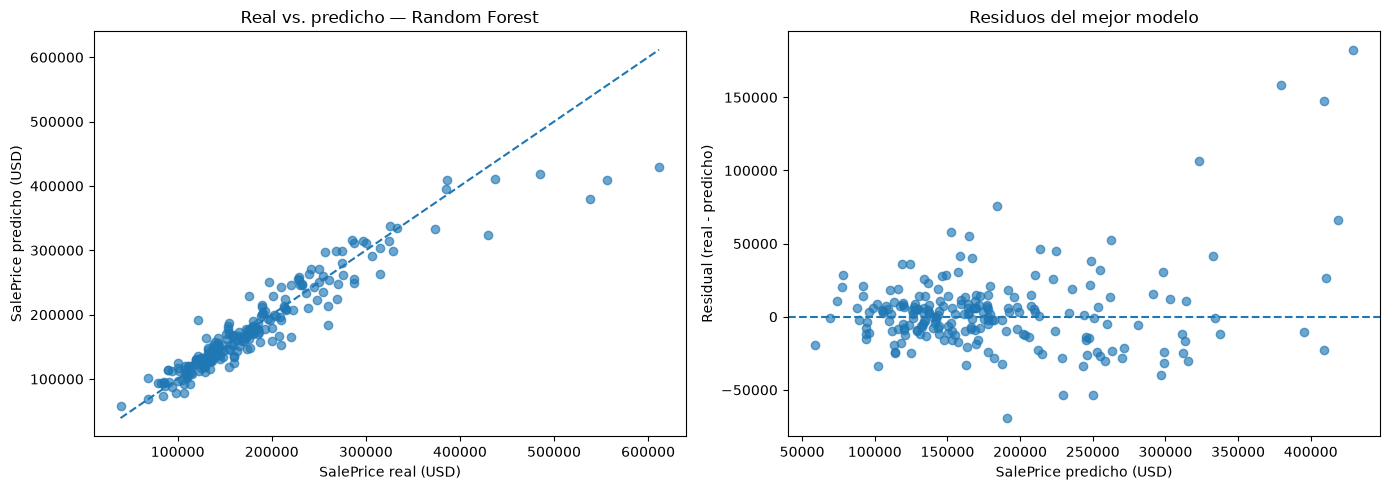

,SalePrice_Real,SalePrice_Predicted,Residual
0,171000,159290.888045,11709.111955
1,200000,158558.134534,41441.865466
2,214000,223724.580230,-9724.580230
3,90000,113760.270859,-23760.270859
4,184900,187346.053930,-2446.053930
5,160000,134159.221444,25840.778556
6,109500,105134.038638,4365.961362
7,115000,107862.100835,7137.899165
8,99900,96338.489876,3561.510124
9,213000,212738.894885,261.105115


In [23]:
best_predictions = validation_predictions[best_model_name]

comparison_df = pd.DataFrame({
    "SalePrice_Real": y_val.to_numpy(),
    "SalePrice_Predicted": best_predictions
})

comparison_df["Residual"] = (
    comparison_df["SalePrice_Real"] - comparison_df["SalePrice_Predicted"]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    comparison_df["SalePrice_Real"],
    comparison_df["SalePrice_Predicted"],
    alpha=0.65
)
min_value = min(
    comparison_df["SalePrice_Real"].min(),
    comparison_df["SalePrice_Predicted"].min()
)
max_value = max(
    comparison_df["SalePrice_Real"].max(),
    comparison_df["SalePrice_Predicted"].max()
)
axes[0].plot([min_value, max_value], [min_value, max_value], linestyle="--")
axes[0].set_xlabel("SalePrice real (USD)")
axes[0].set_ylabel("SalePrice predicho (USD)")
axes[0].set_title(f"Real vs. predicho — {best_model_name}")

axes[1].scatter(
    comparison_df["SalePrice_Predicted"],
    comparison_df["Residual"],
    alpha=0.65
)
axes[1].axhline(0, linestyle="--")
axes[1].set_xlabel("SalePrice predicho (USD)")
axes[1].set_ylabel("Residual (real - predicho)")
axes[1].set_title("Residuos del mejor modelo")

plt.tight_layout()
plt.show()

display(comparison_df.head(10))

## 13. Verificaciones de buenas prácticas y prevención de data leakage

Antes de dar por terminado el experimento, verificar:

1. `AmesFeatureEngineer` aprende medianas, moda y si `Utilities` es constante únicamente al ejecutar `fit` sobre el fold de entrenamiento.
2. `ColumnTransformer` ajusta imputadores, `OrdinalEncoder`, `OneHotEncoder` y `StandardScaler` dentro de cada fold.
3. `RandomizedSearchCV` y `GridSearchCV` reciben solamente `X_train` y `y_train_log`.
4. `X_val` se utiliza únicamente para `predict` y cálculo de métricas al final.
5. Las categorías nuevas en Validation no rompen el pipeline porque One-Hot Encoding usa `handle_unknown="ignore"` y el encoder ordinal usa `unknown_value=-1`.
6. Todas las fuentes de aleatoriedad utilizadas explícitamente tienen una semilla fija.

La transformación `log1p` del target es determinista y no estima parámetros a partir de los datos.

In [24]:
# Auditoría sencilla de los conjuntos originales.
assert "SalePrice" not in X_train.columns
assert "SalePrice" not in X_val.columns
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)

print("Training y Validation permanecen separados.")
print("Validation no fue utilizado en fit() ni en las búsquedas de hiperparámetros.")
print("Semilla global:", RANDOM_STATE)
print("Folds de cross-validation:", N_SPLITS)

Training y Validation permanecen separados.
Validation no fue utilizado en fit() ni en las búsquedas de hiperparámetros.
Semilla global: 42
Folds de cross-validation: 5


## 14. Conclusiones

Completar esta sección luego de ejecutar el notebook:

- ¿Qué modelo obtuvo el menor MAE en Validation?
- ¿Qué modelo obtuvo el menor RMSE en Validation?
- ¿Coinciden ambos criterios? Si no, analizar la presencia de errores grandes.
- ¿Qué diferencia hay entre el RMSE de cross-validation y el RMSE final de Validation?
- ¿Qué hiperparámetros seleccionó cada búsqueda?
- ¿Qué mejoras podrían probarse en una siguiente iteración?

**Importante:** los valores de MAE y RMSE dependen de los CSV utilizados y se calculan al ejecutar las celdas de entrenamiento y evaluación.